# Lecture 7: Bayesian Updating and Overconfidence

**Lecture 7 of 9** · [Series index](README.md)

*This lecture is part of the series that begins with [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb), which adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). The Newton solver is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0. This lecture is shared under the same licence.*

## Overview

[Lecture 6](06_present_bias.ipynb) changed the household's **preferences**: present bias made it discount the near future more heavily than the far future. This lecture changes its **beliefs**.

Every model in the series so far has assumed that agents process information correctly: when new evidence arrives, they update by **Bayes' rule**. Behavioural economics uses that same rule in a second way, as a **benchmark**. Overconfidence is defined, measured and modelled as a systematic, directional departure from what a Bayesian with the same information would believe.

The plan is:

1. why beliefs matter in behavioural economics, and the three distinct things "overconfidence" can mean,
2. Bayes' rule in the two forms used throughout: the **log-odds** form for binary events and the **normal–normal** form for continuous ones,
3. **overprecision** as a misperceived signal precision, with closed forms for forecast errors and the calibration of confidence intervals,
4. what overprecision does in an asset market: **trading volume**, **overreaction** and **return reversals**,
5. **asymmetric updating**, in which good news about oneself is absorbed more fully than bad news, and how it makes agents *learn* to be overconfident,
6. **estimating** updating rules from experimental data by maximum likelihood, solved with the same Newton routine used to solve the macro models in this series,
7. why some apparent overconfidence is perfectly **Bayesian**, and how to test for the real thing, and
8. a short discussion of **motivated beliefs**: why people might prefer to be overconfident.

Almost every result is derived in closed form and then checked by simulation.

## Beliefs in behavioural economics

### Non-standard beliefs

Lecture 6 organised behavioural economics into three kinds of departure from the standard model (DellaVigna, 2009): non-standard **preferences**, non-standard **beliefs** and non-standard **decision-making**. Present bias was the leading example of the first. Overconfidence is the leading example of the second.

The distinction matters. An agent with non-standard preferences can still be perfectly rational given what it wants. An agent with non-standard beliefs makes **mistakes**: it would choose differently if it saw the world correctly. That changes the welfare analysis. Revealed preference no longer identifies what is good for the agent, and better information can make it better off by its own standards.

### Three kinds of overconfidence

Moore and Healy (2008) point out that "overconfidence" is used for three different things, which are measured differently and do not always move together:

| | Definition | Typical measurement |
|---|---|---|
| **Overprecision** | excessive certainty about the accuracy of one's beliefs | confidence intervals that contain the truth less often than claimed |
| **Overestimation** | believing one's ability, performance or chance of success is higher than it is | predicted score above actual score |
| **Overplacement** | believing one is better than others | more than half of people rating themselves above the median |

Some well-known evidence:

- **Calibration studies.** When people give 90% or 98% confidence intervals for uncertain quantities, the intervals contain the truth far less often than claimed (Alpert and Raiffa, 1982; Lichtenstein, Fischhoff and Phillips, 1982). Overprecision is the most robust of the three.
- **Better than average.** Svenson (1981) found that a large majority of US students rated themselves as safer drivers than the median.
- **Trading.** Barber and Odean (2000) found that the households that traded most in their brokerage accounts earned the lowest net returns, consistent with traders overweighting their own information.
- **Executives.** Malmendier and Tate (2005) found that CEOs who kept exercisable in-the-money options well past the rational exercise point, a revealed-preference measure of overconfidence, invested more when their firms had more internal cash.

### Why Bayes' rule is the benchmark

Bayes' rule is not just one way of updating among many. It is the only updating rule that is **coherent**: an agent who updates any other way can be offered a set of bets, each of which looks favourable to it, that together lose money for sure. It also has a sharp testable implication, used repeatedly below: a Bayesian's beliefs are a **martingale**. A Bayesian can't expect its beliefs to drift in any direction, and averaged across a population its beliefs must equal the true frequencies.

So the strategy of the literature, and of this lecture, is:

1. write down the information the agent actually receives,
2. compute what a Bayesian would believe,
3. model the agent as using a **distorted** version of Bayes' rule, with as few extra parameters as possible, and
4. check whether the distortion is identified in data.

This is the same discipline as quasi-hyperbolic discounting in Lecture 6: one extra parameter, with sharp predictions.

## Bayes' rule

### The discrete form

Let $H$ be an event, say "I am in the top half of the ability distribution", and $\neg H$ its complement. The agent starts with a **prior** $\Pr(H)$ and observes a signal $s$. Bayes' rule gives the **posterior**

$$
\Pr(H \mid s) = \frac{\Pr(s \mid H)\,\Pr(H)}{\Pr(s \mid H)\,\Pr(H) + \Pr(s \mid \neg H)\,\Pr(\neg H)}
$$

### The log-odds form

Dividing the expression for $\Pr(H \mid s)$ by the one for $\Pr(\neg H \mid s)$, the denominators cancel:

$$
\frac{\Pr(H \mid s)}{\Pr(\neg H \mid s)} = \frac{\Pr(s \mid H)}{\Pr(s \mid \neg H)} \cdot \frac{\Pr(H)}{\Pr(\neg H)}
$$

Taking logs, and writing $\ell = \log\big(p/(1-p)\big)$ for the **log-odds** or **logit** of a probability $p$,

$$
\boxed{\;\ell_{\text{post}} = \ell_{\text{prior}} + \lambda(s), \qquad \lambda(s) = \log \frac{\Pr(s \mid H)}{\Pr(s \mid \neg H)}\;}
$$

In log-odds, Bayesian updating is **additive**: each signal adds its **log likelihood ratio** $\lambda(s)$. Good news ($\lambda > 0$) moves the logit up and bad news moves it down, by amounts that do not depend on the prior.

**A binary signal.** Throughout the lecture the binary signal is "correct" with probability $a = 0.75$: it says *good* with probability $a$ if $H$ is true and with probability $1-a$ if it is false. Then

$$
\lambda(\text{good}) = \log\frac{a}{1-a} = \log 3 \approx 1.10, \qquad \lambda(\text{bad}) = \log\frac{1-a}{a} = -\log 3
$$

A good and a bad signal cancel exactly, returning a Bayesian to its prior.

### The normal–normal form

For a continuous quantity $\theta$, such as one's own ability or an asset's payoff, let the prior be $\theta \sim N(\mu_0, \sigma_0^2)$ and the signal be $s = \theta + \varepsilon$ with $\varepsilon \sim N(0, \sigma_\varepsilon^2)$ independent of $\theta$. Write $\tau_0 = 1/\sigma_0^2$ and $\tau_s = 1/\sigma_\varepsilon^2$ for the **precisions**.

The posterior density is proportional to prior times likelihood:

$$
p(\theta \mid s) \propto \exp\left\{-\frac{\tau_0}{2}(\theta - \mu_0)^2 - \frac{\tau_s}{2}(s - \theta)^2\right\}
$$

Expanding the exponent and collecting powers of $\theta$,

$$
-\frac{1}{2}\left[(\tau_0 + \tau_s)\,\theta^2 - 2\,(\tau_0 \mu_0 + \tau_s s)\,\theta\right] + \text{const}
= -\frac{\tau_0 + \tau_s}{2}\left(\theta - \frac{\tau_0 \mu_0 + \tau_s s}{\tau_0 + \tau_s}\right)^2 + \text{const}
$$

which is the kernel of a normal density. So $\theta \mid s \sim N(m, v)$ with

$$
\boxed{\; m = \mu_0 + w\,(s - \mu_0), \qquad w = \frac{\tau_s}{\tau_0 + \tau_s}, \qquad v = \frac{1}{\tau_0 + \tau_s}\;}
$$

Two facts drive everything that follows:

- **Precisions add.** Posterior precision is prior precision plus signal precision, $1/v = \tau_0 + \tau_s$.
- **The weight on the signal is its share of total precision.** A more precise signal moves the posterior further.

It is convenient to write $r = \tau_s / \tau_0 = \sigma_0^2/\sigma_\varepsilon^2$ for the **signal-to-noise ratio**, so that $w = r/(1+r)$.

### Beliefs are a martingale

Before the signal arrives, the agent's expectation of its own posterior mean is

$$
\mathbb{E}[m] = \mu_0 + w\,\big(\mathbb{E}[s] - \mu_0\big) = \mu_0
$$

since $\mathbb{E}[s] = \mathbb{E}[\theta] = \mu_0$. In the discrete case, $\mathbb{E}[\Pr(H \mid s)] = \sum_s \Pr(s)\Pr(H\mid s) = \Pr(H)$. This is the **law of iterated expectations**, and it holds for any Bayesian with a correct prior: expected posteriors equal priors. A Bayesian can be surprised, but can't predict the direction of its own surprises. The section on apparent overconfidence uses this to tell real overconfidence apart from the apparent kind.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax.scipy.stats import norm
from jax.scipy.special import logsumexp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

### The code

The Newton routine is the one from Lecture 1, adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html). It is used in the estimation section below.

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x

## Overprecision

### Misperceived signal precision

The standard model of overprecision keeps Bayes' rule but distorts one input. The agent believes its signal is more precise than it really is:

$$
\hat\tau_s = \kappa\, \tau_s, \qquad \kappa > 1
$$

Everything else, including the prior and the formula, is correct. $\kappa = 1$ is the Bayesian, $\kappa > 1$ is overconfident and $\kappa < 1$ is underconfident. This is the specification of Odean (1998) and Daniel, Hirshleifer and Subrahmanyam (1998).

Applying the normal–normal formulas with $\hat\tau_s$ in place of $\tau_s$, the agent's posterior mean and **perceived** variance are

$$
\hat m = \mu_0 + \hat w\,(s - \mu_0), \qquad
\hat w = \frac{\kappa \tau_s}{\tau_0 + \kappa \tau_s} = \frac{\kappa r}{1 + \kappa r}, \qquad
\hat v = \frac{1}{\tau_0 + \kappa \tau_s} = \frac{\sigma_0^2}{1 + \kappa r}
$$

The agent makes two mistakes at once. It **overreacts** to the signal ($\hat w > w$) and it is **too sure** of the result ($\hat v < v$).

### The true forecast error

To see how costly this is, compute the agent's actual forecast error. Using $s - \mu_0 = (\theta - \mu_0) + \varepsilon$,

$$
\theta - \hat m = (\theta - \mu_0) - \hat w\big[(\theta - \mu_0) + \varepsilon\big] = (1 - \hat w)(\theta - \mu_0) - \hat w\, \varepsilon
$$

The two terms are independent, so the **true** error variance is

$$
V(\hat w) \equiv \mathbb{E}\big[(\theta - \hat m)^2\big] = (1 - \hat w)^2 \sigma_0^2 + \hat w^2 \sigma_\varepsilon^2
$$

**Proposition 1 (cost of misweighting).** $V$ is a quadratic in $\hat w$ that is minimised at the Bayesian weight $w$, and

$$
\boxed{\;V(\hat w) - V(w) = (\hat w - w)^2\,(\sigma_0^2 + \sigma_\varepsilon^2)\;}
$$

*Proof.* $V'(\hat w) = -2(1-\hat w)\sigma_0^2 + 2\hat w \sigma_\varepsilon^2$, which is zero at $\hat w = \sigma_0^2/(\sigma_0^2 + \sigma_\varepsilon^2) = w$, and $V''(\hat w) = 2(\sigma_0^2 + \sigma_\varepsilon^2)$. A quadratic is exactly its second-order expansion about its minimum. $\square$

At the minimum, $V(w) = v = 1/(\tau_0 + \tau_s)$: the Bayesian's perceived variance is its true error variance. The Bayesian is **calibrated**. The overconfident agent is not, for two reasons: its errors are larger than the Bayesian's, and it believes they are smaller.

### Calibration of confidence intervals

The agent reports a $(1-\alpha)$ confidence interval $\hat m \pm z\sqrt{\hat v}$, with $z = \Phi^{-1}(1-\alpha/2)$. Because $\theta - \hat m$ is normal with mean zero and variance $V$, the interval actually contains $\theta$ with probability

$$
\Pr\big(|\theta - \hat m| \le z \sqrt{\hat v}\big) = 2\,\Phi\!\left(z\sqrt{\hat v / V}\right) - 1
$$

Using the expressions above in terms of the signal-to-noise ratio $r$,

$$
V = \sigma_0^2 \left[\frac{1}{(1+\kappa r)^2} + \frac{\kappa^2 r^2}{(1+\kappa r)^2}\cdot\frac{1}{r}\right] = \sigma_0^2\,\frac{1 + \kappa^2 r}{(1 + \kappa r)^2},
\qquad
\frac{\hat v}{V} = \frac{1 + \kappa r}{1 + \kappa^2 r}
$$

**Proposition 2 (coverage).** A nominal $(1-\alpha)$ interval has true coverage

$$
\boxed{\;\text{coverage}(\kappa, r) = 2\,\Phi\!\left(z\,\sqrt{\frac{1 + \kappa r}{1 + \kappa^2 r}}\right) - 1\;}
$$

Some implications:

- **Calibration iff Bayesian.** The ratio $\hat v/V$ equals one at $\kappa = 1$, is below one for $\kappa > 1$ (undercoverage) and above one for $\kappa < 1$ (overcoverage).
- **Unbounded miscalibration.** As $\kappa \to \infty$, $\hat v/V \to 0$ and coverage goes to zero.
- **More informative signals make it worse.** For fixed $\kappa > 1$, $\hat v/V$ falls in $r$, towards $1/\kappa$ as $r \to \infty$. Overprecision does the most damage when there is real information to overweight.
- **Only one parameter.** Coverage depends on $\kappa$ and $r$ alone, not on $\mu_0$ or the units of $\theta$. A calibration study that controls the information it gives subjects can therefore recover $\kappa$ from the hit rate.

### A worked example

Take $\mu_0 = 100$, $\sigma_0^2 = \sigma_\varepsilon^2 = 100$ (so $r = 1$ and $w = 0.5$), an observed signal $s = 120$, and $\kappa = 4$. Then $\hat w = 0.8$, $\hat m = 116$ against the Bayesian's $110$, and $\hat v = 20$ against $v = 50$. The true error variance is $V = 0.2^2 \cdot 100 + 0.8^2 \cdot 100 = 68$, and the agent's 90% intervals contain the truth with probability $2\Phi(1.645\sqrt{20/68}) - 1 \approx 63\%$.

The code sets this up and checks Propositions 1 and 2 by simulation.

In [3]:
Belief = namedtuple('Belief', ['mu0', 'sigma0_sq', 'sigma_eps_sq', 'kappa'])


def get_belief(mu0=100.0, sigma0_sq=100.0, sigma_eps_sq=100.0, kappa=4.0):
    return Belief(mu0, sigma0_sq, sigma_eps_sq, kappa)


def weights(b):
    # Bayesian and perceived weights on the signal, and posterior variances.
    tau0, taus = 1 / b.sigma0_sq, 1 / b.sigma_eps_sq
    w = taus / (tau0 + taus)
    w_hat = b.kappa * taus / (tau0 + b.kappa * taus)
    v, v_hat = 1 / (tau0 + taus), 1 / (tau0 + b.kappa * taus)
    return w, w_hat, v, v_hat


def true_error_var(w_hat, b):
    return (1 - w_hat)**2 * b.sigma0_sq + w_hat**2 * b.sigma_eps_sq


def coverage(kappa, r, level=0.90):
    z = norm.ppf(0.5 + level / 2)
    return 2 * norm.cdf(z * jnp.sqrt((1 + kappa * r) / (1 + kappa**2 * r))) - 1


b = get_belief()
w, w_hat, v, v_hat = weights(b)
s_obs = 120.0
z90 = float(norm.ppf(0.95))
for name, ww, vv in [('Bayesian', w, v), ('overconfident (kappa = 4)', w_hat, v_hat)]:
    m = b.mu0 + ww * (s_obs - b.mu0)
    print(f'{name:27s} weight {ww:.2f}  mean {m:6.1f}  variance {vv:5.1f}  '
          f'90% interval [{m - z90*np.sqrt(vv):6.1f}, {m + z90*np.sqrt(vv):6.1f}]')

Bayesian                    weight 0.50  mean  110.0  variance  50.0  90% interval [  98.4,  121.6]
overconfident (kappa = 4)   weight 0.80  mean  116.0  variance  20.0  90% interval [ 108.6,  123.4]


In [4]:
# Check Propositions 1 and 2 by simulation.
n = 2_000_000
k1, k2 = jax.random.split(jax.random.PRNGKey(0))
theta = b.mu0 + jnp.sqrt(b.sigma0_sq) * jax.random.normal(k1, (n,))
s = theta + jnp.sqrt(b.sigma_eps_sq) * jax.random.normal(k2, (n,))
m_hat = b.mu0 + w_hat * (s - b.mu0)

r = b.sigma0_sq / b.sigma_eps_sq
print(f'true error variance:  formula {true_error_var(w_hat, b):.3f}   simulated {jnp.mean((theta - m_hat)**2):.3f}')
print(f'excess over Bayesian: formula {(w_hat - w)**2 * (b.sigma0_sq + b.sigma_eps_sq):.3f}   '
      f'V(w_hat) - V(w) = {true_error_var(w_hat, b) - true_error_var(w, b):.3f}')
print(f'90% coverage:         formula {coverage(b.kappa, r):.4f}   '
      f'simulated {jnp.mean(jnp.abs(theta - m_hat) <= z90 * jnp.sqrt(v_hat)):.4f}')

true error variance:  formula 68.000   simulated 67.996
excess over Bayesian: formula 18.000   V(w_hat) - V(w) = 18.000


90% coverage:         formula 0.6276   simulated 0.6276


The figure shows Proposition 2 across the range of $\kappa$, for three signal-to-noise ratios, alongside the cost in forecast accuracy from Proposition 1 (as a ratio to the Bayesian's error variance, which also depends only on $\kappa$ and $r$). Underconfidence ($\kappa < 1$) produces intervals that are too wide. Overconfidence produces intervals that are too narrow, and much more so when signals are informative.

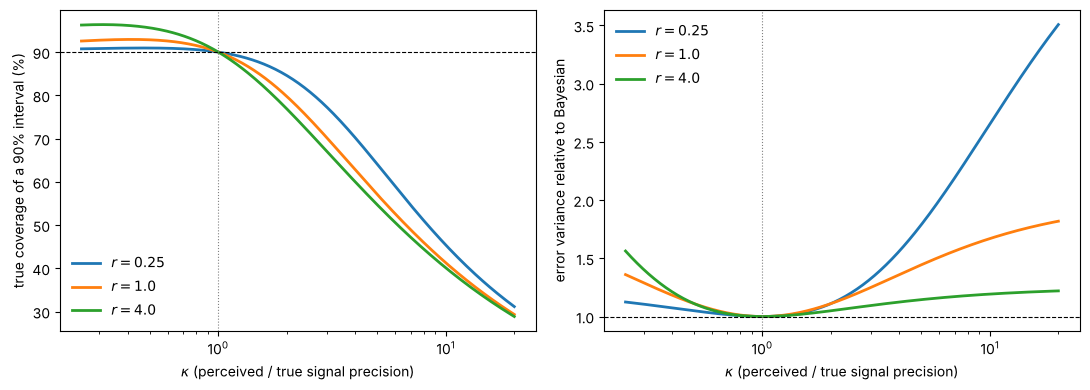

In [5]:
kappas = jnp.exp(jnp.linspace(jnp.log(0.25), jnp.log(20), 300))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for r_ in [0.25, 1.0, 4.0]:
    axes[0].plot(kappas, 100 * coverage(kappas, r_), lw=2, label=f'$r = {r_}$')
    w_r = r_ / (1 + r_)
    wh_r = kappas * r_ / (1 + kappas * r_)
    # V(w_hat)/V(w), using sigma0^2 = 1 and sigma_eps^2 = 1/r
    ratio = ((1 - wh_r)**2 + wh_r**2 / r_) / ((1 - w_r)**2 + w_r**2 / r_)
    axes[1].plot(kappas, ratio, lw=2, label=f'$r = {r_}$')
axes[0].axhline(90, color='k', lw=0.8, ls='--')
axes[0].set_ylabel('true coverage of a 90% interval (%)')
axes[1].axhline(1, color='k', lw=0.8, ls='--')
axes[1].set_ylabel('error variance relative to Bayesian')
for ax in axes:
    ax.set_xscale('log')
    ax.axvline(1, color='grey', lw=0.8, ls=':')
    ax.set_xlabel(r'$\kappa$ (perceived / true signal precision)')
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Overconfidence in markets

Overprecision matters most where people act on their beliefs against each other. The cleanest setting is a market for one risky asset.

### The market

There is a continuum (or a large number $N$) of traders with CARA utility $-e^{-\gamma_a W}$ over terminal wealth, where $\gamma_a$ is absolute risk aversion. A risky asset pays $\theta \sim N(\mu_0, \sigma_0^2)$ at the end. Its supply per trader is $\bar z > 0$, and the safe rate is zero.

A trader whose (perceived) posterior is $\theta \sim N(\hat m_i, \hat v)$ and who buys $x_i$ units at price $p$ has normally distributed terminal wealth, so maximising expected CARA utility is equivalent to maximising the mean–variance objective $x_i(\hat m_i - p) - \tfrac{\gamma_a}{2} x_i^2 \hat v$. Its demand is

$$
x_i = \frac{\hat m_i - p}{\gamma_a \hat v}
$$

Demand is the perceived expected excess return divided by perceived risk. Overprecision raises it twice: through a larger reaction of $\hat m_i$ to news, and through a smaller $\hat v$.

**Date 0.** Before any news, all traders share the prior. Market clearing $x_i = \bar z$ gives $p_0 = \mu_0 - \gamma_a \sigma_0^2 \bar z$, and each trader holds $\bar z$.

**Date 1.** Each trader receives news, forms $\hat m_i$ with weight $\hat w$ and variance $\hat v$, and the market clears again. To keep the algebra transparent, traders here do not try to infer others' information from the price. Odean (1998) studies the version in which they do, and the main results below survive: an overconfident trader still weights its own signal by more than the price justifies.

### Private signals: disagreement and volume

Suppose trader $i$ sees a private signal $s_i = \theta + \varepsilon_i$, with the $\varepsilon_i$ independent. Market clearing, $\frac{1}{N}\sum_i x_i = \bar z$, gives

$$
p_1 = \bar m - \gamma_a \hat v\, \bar z, \qquad \bar m = \frac{1}{N}\sum_i \hat m_i = \mu_0 + \hat w (\bar s - \mu_0)
$$

where $\bar s$ is the average signal. Each trader's **trade** is the change in its position:

$$
x_i - \bar z = \frac{\hat m_i - p_1}{\gamma_a \hat v} - \bar z = \frac{\hat m_i - \bar m}{\gamma_a \hat v} = \frac{\hat w}{\gamma_a \hat v}\,(s_i - \bar s)
$$

and since $\hat w / \hat v = \kappa \tau_s$,

$$
x_i - \bar z = \frac{\kappa\, \tau_s}{\gamma_a}\,(s_i - \bar s)
$$

People trade because they disagree, and how much they trade depends on how seriously each takes its own view. Since $s_i - \bar s = \varepsilon_i - \bar\varepsilon$ is normal with variance $\sigma_\varepsilon^2(1 - 1/N)$, and $\mathbb{E}|X| = \sigma\sqrt{2/\pi}$ for $X \sim N(0, \sigma^2)$:

**Proposition 3 (volume).** Expected trading volume per trader is

$$
\boxed{\;\mathbb{E}\,|x_i - \bar z| = \frac{\kappa}{\gamma_a\, \sigma_\varepsilon}\sqrt{\frac{2}{\pi}\left(1 - \frac{1}{N}\right)}\;}
$$

which is **linear in $\kappa$**. Doubling overconfidence doubles volume. Note too that volume is decreasing in the signal noise $\sigma_\varepsilon$: noisier private signals produce less trade, because a Bayesian, and an overconfident agent in proportion, trusts them less.

None of this trade is useful. In this economy every trader's expected excess return is the same and there are no gains from sharing risk, so the trades only redistribute wealth between traders, at a cost in risk. This is the Barber and Odean (2000) finding in model form: those most confident in their information trade the most.

### A common signal: overreaction and reversal

Now suppose every trader sees the **same** signal $s$, as in Daniel, Hirshleifer and Subrahmanyam (1998), where the "informed" investors share a private signal not yet in the price. There is no disagreement and no trade, but the price moves:

$$
p_1 = \mu_0 + \hat w\,(s - \mu_0) - \gamma_a \hat v\, \bar z
$$

The date-1 price change and the subsequent return, when $\theta$ is revealed, are

$$
\Delta p_1 = p_1 - p_0 = \hat w\,(s - \mu_0) + \gamma_a(\sigma_0^2 - \hat v)\bar z, \qquad
R_2 = \theta - p_1 = (\theta - \mu_0) - \hat w\,(s - \mu_0) + \gamma_a \hat v\, \bar z
$$

Using $\text{Cov}(s, \theta) = \sigma_0^2$ and $\text{Var}(s) = \sigma_0^2 + \sigma_\varepsilon^2$:

**Proposition 4 (overreaction and reversal).**

$$
\boxed{\;\text{Cov}(\Delta p_1, R_2) = \hat w\,\sigma_0^2 - \hat w^2(\sigma_0^2 + \sigma_\varepsilon^2) = \hat w\,(\sigma_0^2 + \sigma_\varepsilon^2)\,(w - \hat w)\;}
$$

- With $\kappa = 1$, $\hat w = w$ and the covariance is zero: Bayesian prices are unpredictable given public information, as an efficient market requires.
- With $\kappa > 1$, the price **overreacts** to the signal, and the overreaction is corrected later: price changes are followed by returns in the opposite direction, a **reversal**.
- The price change is also more volatile than it should be: $\text{Var}(\Delta p_1) = \hat w^2(\sigma_0^2 + \sigma_\varepsilon^2)$ against $w^2(\sigma_0^2 + \sigma_\varepsilon^2)$ for Bayesians.
- The **risk premium** $\mathbb{E}[R_2] = \gamma_a \hat v\, \bar z$ falls with $\kappa$: overconfident investors think the asset is less risky than it is, and price it as such.

Daniel, Hirshleifer and Subrahmanyam add biased self-attribution (the subject of the next section) to this, and show that it produces short-run **momentum** followed by long-run reversal.

The code simulates both versions and checks Propositions 3 and 4.

In [6]:
Market = namedtuple('Market', ['mu0', 'sigma0_sq', 'sigma_eps_sq', 'gamma_a', 'z_bar', 'N'])


def get_market(mu0=100.0, sigma0_sq=100.0, sigma_eps_sq=100.0, gamma_a=2.0, z_bar=1.0, N=50):
    return Market(mu0, sigma0_sq, sigma_eps_sq, gamma_a, z_bar, N)


def perceived(kappa, mk):
    tau0, taus = 1 / mk.sigma0_sq, 1 / mk.sigma_eps_sq
    return kappa * taus / (tau0 + kappa * taus), 1 / (tau0 + kappa * taus)


def simulate_market(kappa, mk, key, R=20_000):
    # R independent draws of the economy; returns volume and the (Delta p1, R2) covariance
    k1, k2, k3 = jax.random.split(key, 3)
    w_hat, v_hat = perceived(kappa, mk)
    theta = mk.mu0 + jnp.sqrt(mk.sigma0_sq) * jax.random.normal(k1, (R,))
    p0 = mk.mu0 - mk.gamma_a * mk.sigma0_sq * mk.z_bar
    # private signals
    s_i = theta[:, None] + jnp.sqrt(mk.sigma_eps_sq) * jax.random.normal(k2, (R, mk.N))
    m_i = mk.mu0 + w_hat * (s_i - mk.mu0)
    p1 = m_i.mean(axis=1) - mk.gamma_a * v_hat * mk.z_bar
    x_i = (m_i - p1[:, None]) / (mk.gamma_a * v_hat)
    volume = jnp.mean(jnp.abs(x_i - mk.z_bar))
    # common signal
    s = theta + jnp.sqrt(mk.sigma_eps_sq) * jax.random.normal(k3, (R,))
    p1c = mk.mu0 + w_hat * (s - mk.mu0) - mk.gamma_a * v_hat * mk.z_bar
    cov = jnp.cov(p1c - p0, theta - p1c)[0, 1]
    premium = jnp.mean(theta - p1c)
    return volume, cov, premium


mk = get_market()
w_bayes, _ = perceived(1.0, mk)
print(f"{'kappa':>6} {'volume':>10} {'formula':>10} {'Cov(dp,R)':>11} {'formula':>10} {'premium':>9} {'formula':>9}")
for kappa in [0.5, 1.0, 2.0, 4.0, 8.0]:
    vol, cov, prem = simulate_market(kappa, mk, jax.random.PRNGKey(1))
    w_hat, v_hat = perceived(kappa, mk)
    vol_f = kappa / (mk.gamma_a * np.sqrt(mk.sigma_eps_sq)) * np.sqrt(2 / np.pi * (1 - 1 / mk.N))
    cov_f = w_hat * (mk.sigma0_sq + mk.sigma_eps_sq) * (w_bayes - w_hat)
    print(f'{kappa:6.1f} {vol:10.4f} {vol_f:10.4f} {cov:11.2f} {cov_f:10.2f} {prem:9.2f} {mk.gamma_a*v_hat*mk.z_bar:9.2f}')

 kappa     volume    formula   Cov(dp,R)    formula   premium   formula


   0.5     0.0197     0.0197       11.58      11.11    133.25    133.33
   1.0     0.0395     0.0395        0.75       0.00     99.92    100.00
   2.0     0.0790     0.0790      -21.16     -22.22     66.59     66.67
   4.0     0.1580     0.1580      -46.66     -48.00     39.93     40.00
   8.0     0.3159     0.3159      -67.60     -69.14     22.15     22.22


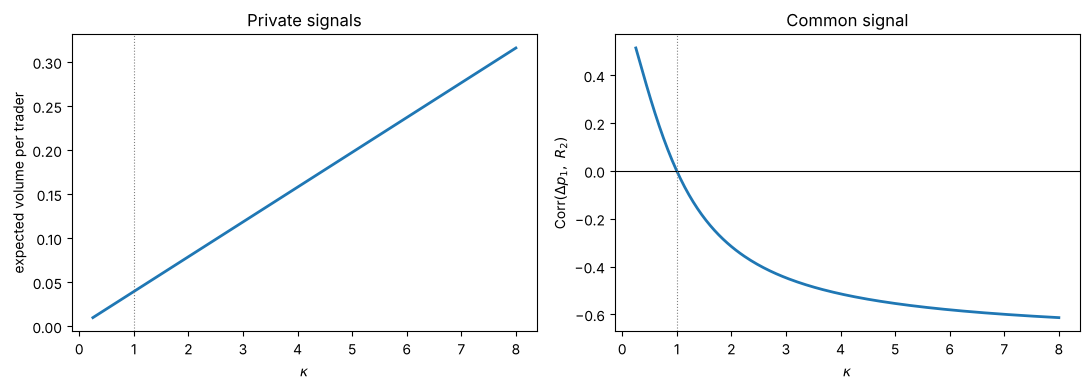

In [7]:
kap = jnp.linspace(0.25, 8, 200)
w_hat, v_hat = perceived(kap, mk)
sd_dp = w_hat * jnp.sqrt(mk.sigma0_sq + mk.sigma_eps_sq)
sd_R2 = jnp.sqrt((1 - w_hat)**2 * mk.sigma0_sq + w_hat**2 * mk.sigma_eps_sq)
corr = w_hat * (mk.sigma0_sq + mk.sigma_eps_sq) * (w_bayes - w_hat) / (sd_dp * sd_R2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(kap, kap / (mk.gamma_a * jnp.sqrt(mk.sigma_eps_sq)) * jnp.sqrt(2 / jnp.pi * (1 - 1 / mk.N)), lw=2)
axes[0].set_ylabel('expected volume per trader')
axes[0].set_title('Private signals')
axes[1].plot(kap, corr, lw=2)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_ylabel(r'Corr$(\Delta p_1,\ R_2)$')
axes[1].set_title('Common signal')
for ax in axes:
    ax.axvline(1, color='grey', lw=0.8, ls=':')
    ax.set_xlabel(r'$\kappa$')
plt.tight_layout()
plt.show()

## Asymmetric updating

Overprecision treats all news alike. The second distortion is about **which** news. When the event is about the agent itself, such as its ability, good news tends to be absorbed more fully than bad news. Psychologists call this **self-serving** or **biased self-attribution**: successes are put down to skill, failures to bad luck.

### The Grether regression

The log-odds form of Bayes' rule suggests a natural way to nest Bayesian and non-Bayesian updating. Following Grether (1980) and Möbius, Niederle, Niehaus and Rosenblat (2022), let the agent's logit after signal $t$ be

$$
\boxed{\;\ell_t = \delta\, \ell_{t-1} + \beta_G\, \lambda_G\, \mathbf{1}\{g_t\} + \beta_B\, \lambda_B\, \mathbf{1}\{\neg g_t\}\;}
$$

where $g_t$ means the signal was good, $\lambda_G = \log 3$ and $\lambda_B = -\log 3$ are the log likelihood ratios, and $(\delta, \beta_G, \beta_B)$ are the updating parameters. Bayes' rule is $\delta = \beta_G = \beta_B = 1$. Each departure has a name:

| Parameter | Departure | Meaning |
|---|---|---|
| $\delta < 1$ | **prior insensitivity** | beliefs are pulled towards 50:50; old information decays |
| $\beta_G, \beta_B < 1$ | **conservatism** | signals move beliefs less than they should |
| $\beta_G > \beta_B$ | **asymmetry** | good news moves beliefs more than equally informative bad news |

Because every term is linear in the parameters, this can be estimated by OLS on elicited beliefs. Möbius et al. find conservatism and asymmetry when subjects update about their own performance on an IQ test, but much less asymmetry when the same signals concern a neutral event. Eil and Rao (2011) find a similar asymmetry for beliefs about one's own intelligence and attractiveness.

### Learning to be overconfident

What do these rules do over many signals? Take $\delta = 1$ first. Then $\ell_t$ is a random walk, and its increment is

$$
\Delta \ell_t = \begin{cases} \beta_G \lambda & \text{with probability } q \\ -\beta_B \lambda & \text{with probability } 1 - q \end{cases}
$$

where $\lambda = \log 3$ and $q$ is the probability of a good signal given the agent's **true** type: $q_H = 0.75$ for a type in the top half, $q_L = 0.25$ for one in the bottom half. The drift is

$$
\boxed{\;\mu(q) = \mathbb{E}[\Delta\ell_t] = \lambda\big(q\, \beta_G - (1 - q)\, \beta_B\big)\;}
$$

and by the law of large numbers $\ell_t / t \to \mu(q)$ almost surely. So beliefs converge to certainty that $H$ is true when $\mu > 0$ and that it is false when $\mu < 0$.

**Proposition 5 (false certainty).** An agent of type $L$ eventually becomes certain it is of type $H$, $\Pr(H) \to 1$, if and only if

$$
\frac{\beta_B}{\beta_G} < \frac{q_L}{1 - q_L} = \frac{1-a}{a} = \frac{1}{3}
$$

A type-$H$ agent always learns the truth when $\beta_B \le \beta_G$. A Bayesian, with $\beta_B / \beta_G = 1$, always learns the truth.

With weaker asymmetry the low type still learns the truth eventually, but **slowly**. With $\beta_G = 1$ and $\beta_B = 0.5$, the type-L drift is $\lambda(0.25 - 0.375) = -0.125\lambda$, a quarter of the Bayesian's $-0.5\lambda$. In the meantime the population as a whole is overconfident: its average belief that it is in the top half is above one half, even though exactly half of it is.

This is the mechanism of Gervais and Odean (2001): traders who attribute successes to their own skill become more overconfident the more they trade, and their overconfidence persists for a long time even though in the long run they learn their true ability.

### Prior insensitivity: persistent miscalibration

With $\delta < 1$, the logit is an AR(1) process driven by i.i.d. shocks, and it no longer converges. Taking expectations of the updating rule, the stationary mean of the logit is $\bar\ell = \delta \bar\ell + \mu(q)$, and taking variances, $\text{Var}(\ell) = \delta^2 \text{Var}(\ell) + \text{Var}(\Delta\ell)$, where $\text{Var}(\Delta \ell) = \lambda^2 q(1-q)(\beta_G + \beta_B)^2$ is the variance of a two-point distribution. So

**Proposition 6 (stationary beliefs).** With $\delta < 1$, the logit has a stationary distribution with

$$
\boxed{\;\mathbb{E}[\ell] = \frac{\lambda\big(q\beta_G - (1-q)\beta_B\big)}{1 - \delta}, \qquad
\text{Var}(\ell) = \frac{\lambda^2\, q(1-q)\,(\beta_G + \beta_B)^2}{1 - \delta^2}\;}
$$

Beliefs never settle down, and with asymmetry the bias never goes away. Each type is permanently miscalibrated in the direction of $\beta_G - \beta_B$.

The code simulates 20,000 agents, half of each type, with `jax.lax.scan` over signals. It checks the Bayesian martingale property, the type-specific limits and Proposition 6.

In [8]:
Updating = namedtuple('Updating', ['delta', 'beta_G', 'beta_B'])
lam = np.log(3)          # log likelihood ratio of a signal with accuracy 0.75
q_H, q_L = 0.75, 0.25    # probability of a good signal by true type


def simulate_beliefs(u, key, n_agents=20_000, T=200, l0=0.0):
    # Logit paths for n_agents, half of them truly in the top half.
    k1, k2 = jax.random.split(key)
    is_H = jax.random.uniform(k1, (n_agents,)) < 0.5
    good = jax.random.uniform(k2, (T, n_agents)) < jnp.where(is_H, q_H, q_L)

    def step(l, g):
        l = u.delta * l + jnp.where(g, u.beta_G * lam, -u.beta_B * lam)
        return l, l

    _, path = jax.lax.scan(step, jnp.full(n_agents, l0), good)
    return is_H, path


def drift(q, u):
    return lam * (q * u.beta_G - (1 - q) * u.beta_B)


cases = {'Bayesian': Updating(1.0, 1.0, 1.0),
         'asymmetric (beta_B = 0.5)': Updating(1.0, 1.0, 0.5),
         'strongly asymmetric (beta_B = 0.25)': Updating(1.0, 1.0, 0.25),
         'asymmetric + prior insensitive (delta = 0.9)': Updating(0.9, 1.0, 0.5)}

sims = {}
print(f"{'':45s} {'mean Pr(H), t=10':>17} {'t=200':>7} {'type H':>7} {'type L':>7}")
for name, u in cases.items():
    is_H, path = simulate_beliefs(u, jax.random.PRNGKey(0))
    p = jax.nn.sigmoid(path)
    sims[name] = (is_H, p)
    print(f'{name:45s} {p[9].mean():17.3f} {p[-1].mean():7.3f} {p[-1][is_H].mean():7.3f} {p[-1][~is_H].mean():7.3f}')

print('\nProposition 5: type-L drift is', {k: round(float(drift(q_L, u)), 3) for k, u in cases.items()})
u = cases['asymmetric + prior insensitive (delta = 0.9)']
is_H, path = simulate_beliefs(u, jax.random.PRNGKey(0))
for label, q, mask in [('type H', q_H, is_H), ('type L', q_L, ~is_H)]:
    mean_f = drift(q, u) / (1 - u.delta)
    var_f = lam**2 * q * (1 - q) * (u.beta_G + u.beta_B)**2 / (1 - u.delta**2)
    print(f'Proposition 6, {label}: mean logit {mean_f:.3f} (sim {path[-1][mask].mean():.3f}), '
          f'variance {var_f:.3f} (sim {path[-1][mask].var():.3f})')

                                               mean Pr(H), t=10   t=200  type H  type L


Bayesian                                                  0.500   0.500   1.000   0.000
asymmetric (beta_B = 0.5)                                 0.648   0.502   1.000   0.005


strongly asymmetric (beta_B = 0.25)                       0.797   0.973   1.000   0.947


asymmetric + prior insensitive (delta = 0.9)              0.654   0.638   0.996   0.280

Proposition 5: type-L drift is {'Bayesian': -0.549, 'asymmetric (beta_B = 0.5)': -0.137, 'strongly asymmetric (beta_B = 0.25)': 0.069, 'asymmetric + prior insensitive (delta = 0.9)': -0.137}


Proposition 6, type H: mean logit 6.866 (sim 6.877), variance 2.680 (sim 2.624)
Proposition 6, type L: mean logit -1.373 (sim -1.353), variance 2.680 (sim 2.642)


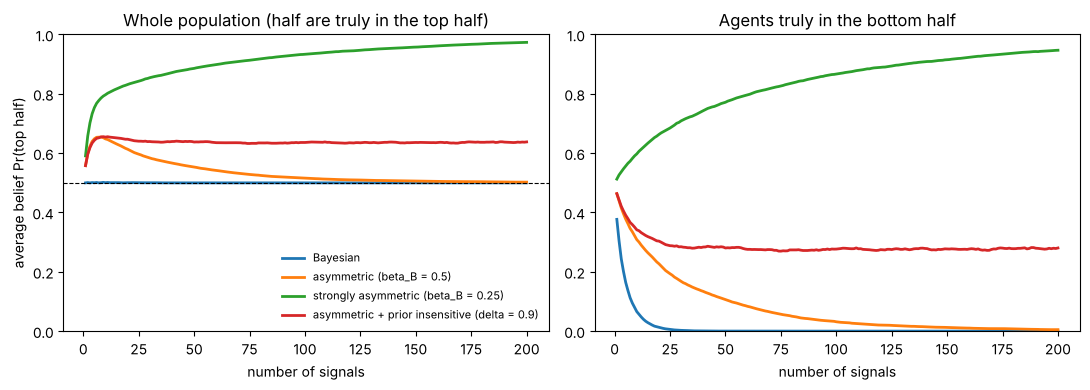

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
t = np.arange(1, 201)
for name, (is_H, p) in sims.items():
    axes[0].plot(t, p.mean(axis=1), lw=2, label=name)
    axes[1].plot(t, p[:, ~is_H].mean(axis=1), lw=2, label=name)
axes[0].axhline(0.5, color='k', lw=0.8, ls='--')
axes[0].set_title('Whole population (half are truly in the top half)')
axes[0].set_ylabel('average belief Pr(top half)')
axes[1].set_title('Agents truly in the bottom half')
for ax in axes:
    ax.set_xlabel('number of signals')
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

The Bayesian population's average belief stays at exactly one half, as the martingale property requires, while each individual Bayesian quickly learns its type. With moderate asymmetry, the population is overconfident for a long time, but eventually learns. With strong asymmetry, low types become certain they are high types. With prior insensitivity, the population settles at a permanent level of overconfidence.

## Estimating updating rules with Newton's method

How would we measure $(\delta, \beta_G, \beta_B)$? This section simulates an experiment like that of Möbius et al. (2022), estimates the updating rule, and shows why heterogeneity across subjects matters.

### The experiment

Each of $n = 1{,}000$ subjects takes a test, and the experimenter knows whether each scored in the top half. Subjects report their belief that they are in the top half, and then receive four binary signals of accuracy $0.75$ about it, reporting an updated belief after each. Beliefs are elicited with an incentive-compatible mechanism, so the reports can be taken as the subjects' true beliefs, up to noise.

The simulated population contains two types:

- a share $\pi$ of **Bayesians**, with $\delta = \beta_G = \beta_B = 1$, and
- a share $1 - \pi$ of **biased updaters**, with prior insensitivity, mild conservatism about good news, and strong discounting of bad news.

Reported logits follow the Grether rule plus noise, $\ell_{it} = \delta_j \ell_{i,t-1} + \beta_{Gj}\lambda\mathbf{1}\{g_{it}\} - \beta_{Bj}\lambda\mathbf{1}\{\neg g_{it}\} + \eta_{it}$, with $\eta_{it} \sim N(0, \sigma^2)$, where $\ell_{i,t-1}$ is the subject's previous **reported** belief. The parameter values are illustrative, not estimates from the literature.

In [10]:
Experiment = namedtuple('Experiment', ['n', 'rounds', 'pi_bayes', 'delta', 'beta_G', 'beta_B', 'sigma'])


def get_experiment(n=1000, rounds=4, pi_bayes=0.4, delta=0.9, beta_G=0.9, beta_B=0.4, sigma=0.3):
    return Experiment(n, rounds, pi_bayes, delta, beta_G, beta_B, sigma)


def simulate_experiment(e, key):
    ks = jax.random.split(key, 5)
    bayes = jax.random.uniform(ks[0], (e.n,)) < e.pi_bayes
    is_H = jax.random.uniform(ks[1], (e.n,)) < 0.5
    good = jax.random.uniform(ks[2], (e.rounds, e.n)) < jnp.where(is_H, q_H, q_L)
    eta = e.sigma * jax.random.normal(ks[3], (e.rounds, e.n))
    d = jnp.where(bayes, 1.0, e.delta)
    bG = jnp.where(bayes, 1.0, e.beta_G)
    bB = jnp.where(bayes, 1.0, e.beta_B)
    logits = [0.5 * jax.random.normal(ks[4], (e.n,))]      # heterogeneous initial beliefs
    for t in range(e.rounds):
        logits.append(d * logits[-1] + jnp.where(good[t], bG * lam, -bB * lam) + eta[t])
    L = jnp.stack(logits)
    return L[:-1], L[1:], good.astype(float), bayes      # prior, posterior, signals, true type


e = get_experiment()
prior, post, good, bayes = simulate_experiment(e, jax.random.PRNGKey(3))

### Pooled OLS

Stacking all subjects and rounds, the Grether regression of $\ell_{it}$ on $\ell_{i,t-1}$, $\lambda\mathbf{1}\{g_{it}\}$ and $-\lambda\mathbf{1}\{\neg g_{it}\}$ (no constant) estimates a single set of parameters for everyone.

In [11]:
X = jnp.stack([prior.ravel(), lam * good.ravel(), -lam * (1 - good).ravel()], axis=1)
y = post.ravel()
coef = jnp.linalg.lstsq(X, y)[0]
sigma_ols = jnp.std(y - X @ coef)
print('pooled OLS:  delta = {:.3f}, beta_G = {:.3f}, beta_B = {:.3f}, sigma = {:.3f}'.format(*coef, sigma_ols))

pooled OLS:  delta = 0.981, beta_G = 0.918, beta_B = 0.631, sigma = 0.394


The pooled estimates find conservatism and asymmetry, but describe nobody: no subject in the population has these parameters. They average a group that is exactly Bayesian with a group that is much more biased, and the residual spread $\hat\sigma$ is inflated by the mismatch. For welfare and policy, the distinction matters. A population in which everyone is mildly biased calls for different responses from one in which a minority is strongly biased.

### A mixture model

To recover the two groups, we estimate the **finite mixture**. A subject's four reports are independent normal given its type, so the likelihood of subject $i$'s data is

$$
\mathcal{L}_i(\vartheta) = \pi \prod_{t=1}^{4} \frac{1}{\sigma}\phi\!\left(\frac{e^{B}_{it}}{\sigma}\right)
+ (1 - \pi) \prod_{t=1}^{4} \frac{1}{\sigma}\phi\!\left(\frac{e^{A}_{it}(\delta, \beta_G, \beta_B)}{\sigma}\right)
$$

where $e^B_{it}$ and $e^A_{it}$ are the residuals of the Bayesian and biased updating rules. We parameterise $\vartheta = (\operatorname{logit}\pi, \delta, \beta_G, \beta_B, \log\sigma)$ so that it is unconstrained, and maximise $\sum_i \log \mathcal{L}_i(\vartheta)$, computed with `logsumexp` for numerical stability.

### The maximum likelihood estimator as a root-finding problem

The maximum likelihood estimator solves the **score equations**

$$
\nabla_\vartheta \log \mathcal{L}(\hat\vartheta) = 0
$$

a square system of five nonlinear equations in five unknowns. That is exactly the kind of problem the Newton routine in this series solves. JAX gives the score by automatic differentiation, and the Newton routine differentiates it again to get the Hessian, so

$$
\vartheta^{(n+1)} = \vartheta^{(n)} - \left[\nabla^2 \log \mathcal{L}\big(\vartheta^{(n)}\big)\right]^{-1} \nabla \log \mathcal{L}\big(\vartheta^{(n)}\big)
$$

This is the classic **Newton–Raphson** method for maximum likelihood. Just as in the macro models, the same code solves a stacked system of first-order conditions; here they are the first-order conditions of the econometrician rather than of households and firms. As there, we use a damped first pass (`adj = 0.3`) from a reasonable starting point, the pooled OLS estimates, and then full Newton steps.

The Hessian at the solution has a second use. Its negative inverse is the asymptotic variance of the estimator, so standard errors come for free.

In [12]:
def unpack(theta):
    return jax.nn.sigmoid(theta[0]), theta[1], theta[2], theta[3], jnp.exp(theta[4])


def loglik(theta, prior, post, good):
    pi, d, bG, bB, sigma = unpack(theta)

    def type_loglik(d, bG, bB):
        resid = post - (d * prior + good * bG * lam - (1 - good) * bB * lam)
        return jnp.sum(-0.5 * (resid / sigma)**2 - jnp.log(sigma) - 0.5 * jnp.log(2 * jnp.pi), axis=0)

    per_subject = logsumexp(jnp.stack([jnp.log(pi) + type_loglik(1.0, 1.0, 1.0),
                                       jnp.log1p(-pi) + type_loglik(d, bG, bB)]), axis=0)
    return jnp.sum(per_subject)


ll = lambda theta: loglik(theta, prior, post, good)
score = jax.grad(ll)

theta0 = jnp.array([0.0, coef[0], coef[1], coef[2], jnp.log(sigma_ols)])
theta1 = newton(score, theta0, tol=1e-6, max_iter=200, adj=0.3)
theta_hat = newton(score, theta1, tol=1e-10, max_iter=50, verbose=True)

H = jax.hessian(ll)(theta_hat)
print('\nHessian eigenvalues (all negative at a maximum):', np.round(np.asarray(jnp.linalg.eigvalsh(H)), 1))

iteration 1, error = 2.303516924733574e-06
iteration 2, error = 1.416015777169217e-12



Hessian eigenvalues (all negative at a maximum): [-30285.5 -15012.8 -10559.9  -7261.5   -176.6]


In [13]:
# Standard errors by the delta method: Var(g(theta_hat)) = J Var(theta_hat) J'
cov_theta = jnp.linalg.inv(-H)
g = lambda th: jnp.stack(unpack(th))
J = jax.jacobian(g)(theta_hat)
se = jnp.sqrt(jnp.diag(J @ cov_theta @ J.T))
est = g(theta_hat)
truth = [e.pi_bayes, e.delta, e.beta_G, e.beta_B, e.sigma]
print(f"{'':10s} {'true':>7} {'estimate':>9} {'s.e.':>7}")
for name, tv, ev, sv in zip(['pi', 'delta', 'beta_G', 'beta_B', 'sigma'], truth, est, se):
    print(f'{name:10s} {tv:7.3f} {ev:9.3f} {sv:7.3f}')
print(f'\nscore at the estimate: {jnp.max(jnp.abs(score(theta_hat))):.2e}')

              true  estimate    s.e.
pi           0.400     0.387   0.018
delta        0.900     0.901   0.006
beta_G       0.900     0.893   0.009
beta_B       0.400     0.396   0.008
sigma        0.300     0.301   0.004



score at the estimate: 1.12e-12


Newton's method converges in a couple of full steps from the damped first pass, and the mixture recovers the share of Bayesians and the biased group's parameters, with tight standard errors. The pooled regression had found $\hat\beta_B$ well above the biased group's true value, because it was averaging in the Bayesians.

One caution, familiar from the macro lectures: Newton's method finds a root of the score, not necessarily the maximum. The check that every eigenvalue of the Hessian is negative confirms that this root is a local maximum. Mixture likelihoods can have several local maxima, so in practice one would try several starting points.

## Apparent overconfidence

The better-than-average effect is the most famous evidence of overconfidence: in survey after survey, well over half of people rate themselves above the median. But Benoît and Dubra (2011) show that this, on its own, is **not** evidence of any bias. Perfectly Bayesian agents can produce it.

### A Bayesian driving example

Half the population are good drivers and half bad. Each person has driven for a year. Good drivers never have an accident; bad drivers have one with probability $p_a = 0.4$. Nobody knows their type, everyone knows these facts, and everyone updates correctly.

- Those who **had an accident** know they are bad: $\Pr(\text{good} \mid \text{accident}) = 0$.
- Those who **didn't** compute

$$
\Pr(\text{good} \mid \text{no accident}) = \frac{0.5 \times 1}{0.5 \times 1 + 0.5 \times (1 - p_a)} = \frac{1}{2 - p_a} = 0.625
$$

The share who had no accident is $1 - p_a/2 = 80\%$. So **80% of this population believe they are more likely than not to be better than the median**, and every one of them is a correct Bayesian.

### What Bayes' rule does restrict

What Bayes' rule pins down is the **average** belief, not the share above one half. By the martingale property, beliefs average to the truth across a population with a common, correct prior:

$$
\mathbb{E}\big[\Pr(\text{top half} \mid \text{information})\big] = \Pr(\text{top half}) = \frac{1}{2}
$$

In the example, $0.8 \times 0.625 + 0.2 \times 0 = 0.5$. Now suppose a fraction $f$ of the population report that they are in the top half with probability **at least** $q$. Since beliefs are non-negative, the average belief is at least $fq$, so

$$
\boxed{\; f\, q \le \frac{1}{2}\;}
$$

This is a necessary condition for Bayesian beliefs, and Benoît and Dubra show that it is essentially also sufficient: any data satisfying it can be generated by some Bayesian population. In the example, $f = 0.8$ and $q = 0.625$, and $fq = 0.5$ exactly. Data in which 80% of people say they are at least 90% sure they are above the median, $fq = 0.72$, could not come from Bayesians.

The lesson is about **measurement**. "Do you think you're above average?" can't detect overconfidence. Questions that elicit full probabilities can.

### The hard–easy effect

The same logic explains a pattern Moore and Healy (2008) emphasise: people tend to rate themselves above others on **easy** tasks and below others on **hard** ones.

Let ability be $\theta \sim N(0, 1)$, so the median is zero. Each person attempts a task and **succeeds** if $\theta + \varepsilon > c$, where $\varepsilon \sim N(0, \sigma^2)$ is luck and $c$ is the **difficulty**. Success is good news about $\theta$, because its probability rises with $\theta$. So for a Bayesian,

$$
\Pr(\theta > 0 \mid \text{success}) > \frac{1}{2} > \Pr(\theta > 0 \mid \text{failure})
$$

The share of people who believe they are above the median is therefore the share who succeed:

$$
\boxed{\;\text{share above-median believers} = \Pr(\theta + \varepsilon > c) = \Phi\!\left(\frac{-c}{\sqrt{1 + \sigma^2}}\right)\;}
$$

which is above one half for easy tasks ($c < 0$) and below one half for hard ones ($c > 0$). Bayesians show **overplacement on easy tasks and underplacement on hard ones**, with no bias at all. The posterior beliefs themselves are bivariate normal probabilities:

$$
\Pr(\theta > 0 \mid \text{success}) = \frac{\Pr(\theta > 0,\ \theta + \varepsilon > c)}{\Phi\big(-c/\sqrt{1+\sigma^2}\big)}
$$

The code computes the beliefs by simulation, checks the share formula, and checks that average beliefs are one half at every level of difficulty.

In [14]:
def hard_easy(c, sigma, key, n=1_000_000):
    k1, k2 = jax.random.split(key)
    theta = jax.random.normal(k1, (n,))
    success = theta + sigma * jax.random.normal(k2, (n,)) > c
    p_succ = jnp.mean(success)
    belief_succ = jnp.mean((theta > 0) & success) / p_succ
    belief_fail = jnp.mean((theta > 0) & ~success) / (1 - p_succ)
    avg_belief = p_succ * belief_succ + (1 - p_succ) * belief_fail
    return p_succ, belief_succ, belief_fail, avg_belief


sigma_luck = 1.0
print(f"{'difficulty c':>12} {'share > 1/2':>12} {'formula':>8} {'Pr(top|succ)':>13} {'Pr(top|fail)':>13} {'mean belief':>12}")
for c in [-1.5, -0.5, 0.0, 0.5, 1.5]:
    ps, bs, bf, avg = hard_easy(c, sigma_luck, jax.random.PRNGKey(7))
    print(f'{c:12.1f} {ps:12.3f} {norm.cdf(-c / np.sqrt(1 + sigma_luck**2)):8.3f} {bs:13.3f} {bf:13.3f} {avg:12.3f}')

difficulty c  share > 1/2  formula  Pr(top|succ)  Pr(top|fail)  mean belief


        -1.5        0.856    0.856         0.571         0.073        0.499
        -0.5        0.638    0.638         0.679         0.182        0.499
         0.0        0.500    0.500         0.748         0.250        0.499


         0.5        0.362    0.362         0.817         0.319        0.499
         1.5        0.144    0.144         0.929         0.427        0.499


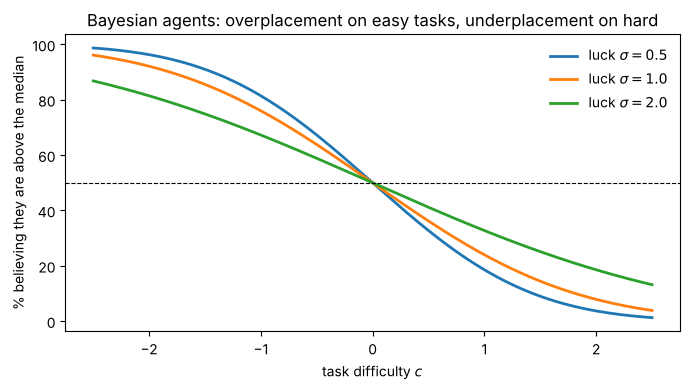

In [15]:
cs = jnp.linspace(-2.5, 2.5, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for sig in [0.5, 1.0, 2.0]:
    ax.plot(cs, 100 * norm.cdf(-cs / jnp.sqrt(1 + sig**2)), lw=2, label=rf'luck $\sigma = {sig}$')
ax.axhline(50, color='k', lw=0.8, ls='--')
ax.set_xlabel('task difficulty $c$')
ax.set_ylabel('% believing they are above the median')
ax.set_title('Bayesian agents: overplacement on easy tasks, underplacement on hard')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

More luck (larger $\sigma$) flattens the curve: success is then less informative, so fewer people move far from the prior. In every case the mean belief is exactly one half, which is the testable restriction.

## Motivated beliefs

The sections on overprecision and asymmetric updating modelled overconfidence as a mistake. A growing literature asks instead why people might **want** to hold optimistic beliefs, and treats beliefs as partly chosen.

- **Self-confidence as an asset.** Bénabou and Tirole (2002) model a person whose motivation depends on their confidence in their own ability. An agent who knows it will be tempted to quit can rationally prefer to remember successes more readily than failures, because the resulting confidence keeps it working. Selective memory then produces the same pattern as asymmetric updating, $\beta_G > \beta_B$, as a strategy rather than an error.
- **Optimal expectations.** Brunnermeier and Parker (2005) let agents choose beliefs to maximise expected well-being, which includes the pleasure of anticipating good outcomes, while still choosing actions optimally given those beliefs. Optimism raises anticipatory utility but distorts decisions, and the optimal beliefs trade these off. The model predicts overconfidence, preference for skewed assets and under-diversification.
- **Evidence.** The finding of Möbius et al. that asymmetry appears for ego-relevant beliefs but not for neutral ones fits this view: people distort the beliefs they care about, not all beliefs.

These models matter for policy in the same way as present bias did in Lecture 6. If overconfidence is a pure mistake, better information helps. If it is partly chosen, people may resist the information, and correcting their beliefs may make them worse off by some measures even as it improves their decisions.

## Summary

| | Distortion | Signature | Closed form |
|---|---|---|---|
| Overprecision | perceived signal precision $\kappa\tau_s$ | intervals too narrow, overreaction, trade | coverage $2\Phi\big(z\sqrt{(1+\kappa r)/(1+\kappa^2 r)}\big) - 1$ |
| Asymmetric updating | $\beta_G > \beta_B$ in log-odds | beliefs drift up, learning to be overconfident | drift $\lambda(q\beta_G - (1-q)\beta_B)$ |
| Prior insensitivity | $\delta < 1$ | beliefs never settle | stationary mean $\mu(q)/(1-\delta)$ |
| Apparent overconfidence | none | most think they're above median | Bayesian iff $fq \le 1/2$ |

In each case, Bayes' rule is what makes the distortion **measurable**. It tells us what a correctly calibrated agent would believe, and the martingale property tells us what Bayesian beliefs must average to, which is what separates real overconfidence from the apparent kind.

## Exercises

1. **Underreaction.** Show that with $\kappa < 1$, Proposition 4 gives $\text{Cov}(\Delta p_1, R_2) > 0$: prices underreact and returns show momentum. What kind of agent is this?
2. **Coverage.** Invert Proposition 2: given an observed hit rate of 50% for 90% intervals and a known $r = 1$, solve for $\kappa$. Do this with the `newton` routine applied to $\text{coverage}(\kappa, r) - 0.5 = 0$.
3. **Learning in the market.** In the private-signal market, add a second date of trade. Show that if traders update $\kappa$ by asymmetric attribution after observing their profits (larger after gains than losses), volume rises over time for traders who were lucky early.
4. **Monte Carlo.** Repeat the simulated experiment two hundred times. Compare the mean and spread of the mixture estimates with the Hessian-based standard errors. How small can $n$ get before the mixture becomes hard to estimate?
5. **Benoît–Dubra.** In the hard–easy model, compute the fraction $f$ of people whose belief that they are above the median is at least $q = 0.7$, as a function of $c$. Verify that $f\,q \le 1/2$ always holds.

## References

- Alpert, M. and Raiffa, H. (1982). A progress report on the training of probability assessors. In D. Kahneman, P. Slovic and A. Tversky (eds), *Judgment under Uncertainty: Heuristics and Biases*. Cambridge University Press.
- Barber, B. M. and Odean, T. (2000). Trading is hazardous to your wealth: the common stock investment performance of individual investors. *Journal of Finance*, 55(2), 773–806.
- Benjamin, D. J. (2019). Errors in probabilistic reasoning and judgment biases. In B. D. Bernheim, S. DellaVigna and D. Laibson (eds), *Handbook of Behavioral Economics*, Vol. 2. North-Holland.
- Bénabou, R. and Tirole, J. (2002). Self-confidence and personal motivation. *Quarterly Journal of Economics*, 117(3), 871–915.
- Benoît, J.-P. and Dubra, J. (2011). Apparent overconfidence. *Econometrica*, 79(5), 1591–1625.
- Brunnermeier, M. K. and Parker, J. A. (2005). Optimal expectations. *American Economic Review*, 95(4), 1092–1118.
- Daniel, K., Hirshleifer, D. and Subrahmanyam, A. (1998). Investor psychology and security market under- and overreactions. *Journal of Finance*, 53(6), 1839–1885.
- DellaVigna, S. (2009). Psychology and economics: evidence from the field. *Journal of Economic Literature*, 47(2), 315–372.
- Eil, D. and Rao, J. M. (2011). The good news-bad news effect: asymmetric processing of objective information about yourself. *American Economic Journal: Microeconomics*, 3(2), 114–138.
- Gervais, S. and Odean, T. (2001). Learning to be overconfident. *Review of Financial Studies*, 14(1), 1–27.
- Grether, D. M. (1980). Bayes rule as a descriptive model: the representativeness heuristic. *Quarterly Journal of Economics*, 95(3), 537–557.
- Lichtenstein, S., Fischhoff, B. and Phillips, L. D. (1982). Calibration of probabilities: the state of the art to 1980. In D. Kahneman, P. Slovic and A. Tversky (eds), *Judgment under Uncertainty: Heuristics and Biases*. Cambridge University Press.
- Malmendier, U. and Tate, G. (2005). CEO overconfidence and corporate investment. *Journal of Finance*, 60(6), 2661–2700.
- Möbius, M. M., Niederle, M., Niehaus, P. and Rosenblat, T. S. (2022). Managing self-confidence: theory and experimental evidence. *Management Science*, 68(11), 7793–7817.
- Moore, D. A. and Healy, P. J. (2008). The trouble with overconfidence. *Psychological Review*, 115(2), 502–517.
- Odean, T. (1998). Volume, volatility, price, and profit when all traders are above average. *Journal of Finance*, 53(6), 1887–1934.
- Svenson, O. (1981). Are we all less risky and more skillful than our fellow drivers? *Acta Psychologica*, 47(2), 143–148.